In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from data_utils import plot_bump

data = {}
for f in sorted(Path("data_clean").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

print(list(data.keys()))

ImportError: cannot import name 'plot_bump' from 'data_utils' (c:\Drive_D\Roadscanners\SemesterProjectFall2026\Nihar\data_utils.py)

In [ ]:
Path("figures").mkdir(exist_ok=True)

### Section 1: what does a bump look like?

#### 2: where are the frost heaves in the 80 km/h drive?

In [ ]:
df = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"]

heave = df["muu"] == 1
starts = df.loc[heave & ~heave.shift(fill_value=False), "Loc(m)"]
print(starts.round().tolist())

[4227.0, 4791.0, 4932.0, 5046.0, 5168.0, 5371.0, 5388.0, 5658.0, 6245.0, 6598.0, 6702.0]


#### 3: zoom in on one bump, in three sensors at once

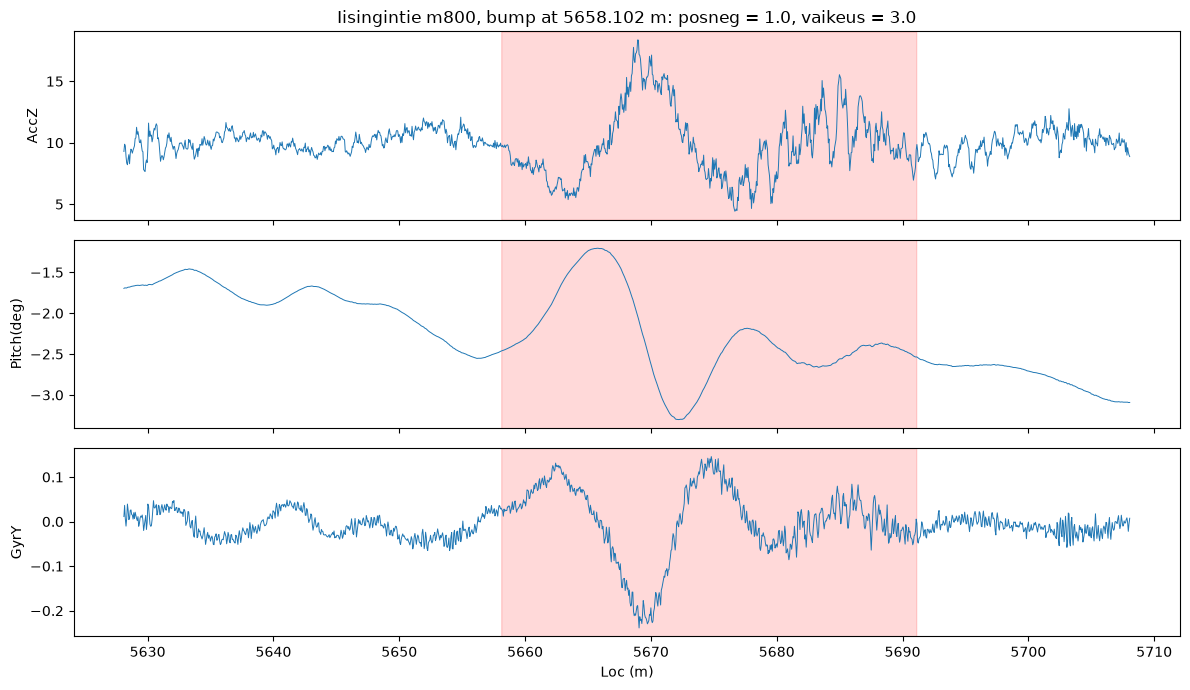

In [ ]:
center = starts.iloc[7]          # the first bump; try others from the list above
part = df[df["Loc(m)"].between(center - 30, center + 50)]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, col in zip(axes, ["AccZ", "Pitch(deg)", "GyrY"]):
    ax.plot(part["Loc(m)"], part[col], linewidth=0.7)
    ax.fill_between(part["Loc(m)"], 0, 1, where=part["muu"] == 1,
                    transform=ax.get_xaxis_transform(), color="red", alpha=0.15)
    ax.set_ylabel(col)

row = part[part["muu"] == 1].iloc[0]
axes[0].set_title(f"Iisingintie m800, bump at {center} m: posneg = {row['posneg']}, vaikeus = {row['vaikeus']}")
axes[-1].set_xlabel("Loc (m)")
plt.tight_layout()
plt.show()

* Most of the time, inside a bump, the signal fluctuates more. Outside it's calm

* That's exactly what model will use later. When we cut the road into windows, we’ll compute numbers like “how much does the signal vary in this window?” (standard deviation) or “how big is the biggest swing?” (peak-to-peak). A window with a bump should score high and a calm window low.

### Section 2: does an up bump look different from a down bump?

#### 1: list the bumps with their type and size

In [ ]:
starts_idx = df.index[heave & ~heave.shift(fill_value=False)]
bumps = df.loc[starts_idx, ["Loc(m)", "posneg", "vaikeus"]].round(0)
print(bumps.to_string(index=False))

 Loc(m)  posneg  vaikeus
 4227.0       1        5
 4791.0       1        3
 4932.0       1        1
 5046.0       1        3
 5168.0       1        5
 5371.0       1        1
 5388.0       1        2
 5658.0       1        3
 6245.0       1        5
 6598.0       1        5
 6702.0       1        5


In [ ]:
for f in sorted(Path("../dataset").glob("*.txt")):
    raw = pd.read_csv(f, sep="\t", dtype=str)
    posneg = pd.to_numeric(raw["posneg"].str.replace(",", "."))
    print(f"{f.stem[:30]:32} highest posneg in raw file: {posneg.max():.2f}")

Iisingintie_Acc1_m800_RDMC_202   highest posneg in raw file: 1.00
Iisingintie_Acc1_m801_RDMC_202   highest posneg in raw file: 1.00
Iisingintie_Acc1_m802_RDMC_202   highest posneg in raw file: 1.00
Kaittiaisentie_Acc1_RDMC_2026-   highest posneg in raw file: 2.00
sinetänsalmentie_Acc1_m792_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m793_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m794_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m795_RDM   highest posneg in raw file: 1.00


In [ ]:
rows = []
for name, df in data.items():
    marked = df["muu"] != 0
    new = marked & ~marked.shift(fill_value=False)
    block = new.cumsum()
    for _, g in df[marked].groupby(block[marked]):
        rows.append({
            "file":     name.split("_RDMC")[0],
            "start":    round(g["Loc(m)"].iloc[0]),
            "length_m": round(g["Loc(m)"].iloc[-1] - g["Loc(m)"].iloc[0], 1),
            "muu":      g["muu"].mode()[0],
            "posneg":   g["posneg"].mode()[0],
            "vaikeus":  g["vaikeus"].mode()[0],
        })

stretches = pd.DataFrame(rows)
print(pd.crosstab(stretches["muu"], stretches["posneg"]))

posneg  0   1  2
muu             
1       0  43  4
2       0   1  0
3       9   0  0
4       0   6  0
5       3   0  0


In [ ]:
k = data["Kaittiaisentie_Acc1_RDMC_2026-05-06_132147"]

print(stretches[(stretches["file"].str.startswith("Kaittiaisentie")) & (stretches["muu"] == 1)]
      .to_string(index=False))

               file  start  length_m  muu  posneg  vaikeus
Kaittiaisentie_Acc1     76      15.0    1       2        3
Kaittiaisentie_Acc1    395      22.0    1       1        1
Kaittiaisentie_Acc1    873      11.0    1       2        1
Kaittiaisentie_Acc1   1160      20.0    1       1        3
Kaittiaisentie_Acc1   2308      28.0    1       2        1
Kaittiaisentie_Acc1   3005      33.0    1       2        5


In [ ]:
up_bump = 395      # start of a posneg = 1 bump
down_bump = 76     # start of a posneg = 2 bump

plot_bump(k, up_bump, f"Kaittiaisentie: UP bump at {up_bump} m").savefig("figures/up_bump.png", dpi=150)
plot_bump(k, down_bump, f"Kaittiaisentie: DOWN bump at {down_bump} m").savefig("figures/down_bump.png", dpi=150)
plt.show()

NameError: name 'plot_bump' is not defined